# 38 · Capstone: the support desk in production
Level L6 · Part 6 · project · ~90 min · builds on 14, 32, 33, 34, 35, 36, 37

## Goal
Put the parts of the course into one service: a desk graph that classifies a message with the model, looks up the order, pauses any refund for
a person, pays each refund once under its key, gates every write against identity and scope, keeps a spend cap per ticket, and writes an audit
entry for each decision. Then check each production requirement against a run, the way a release review does.

## Why it matters
Each lesson showed one part working. A production agent is the parts together, and the parts meet at the places where they fail: a refund that
pauses while the cap runs out, a retry that finds an approval it should not, a log that holds a message it should not. The capstone is the review
that finds those meetings before a customer does.

## The idea
The desk is one graph. The model classifies; code does the rest. Writes are gated in code, the payment is keyed, the cap is checked after each
model call, and the audit log is written at each decision. The release gate runs last, on the same golden set, and the review at the end reads the
results.

## Picture
The diagram is drawn by `show_mermaid`, a course helper in `graph_view.py` that turns Mermaid text into a picture (offline, it prints the text).

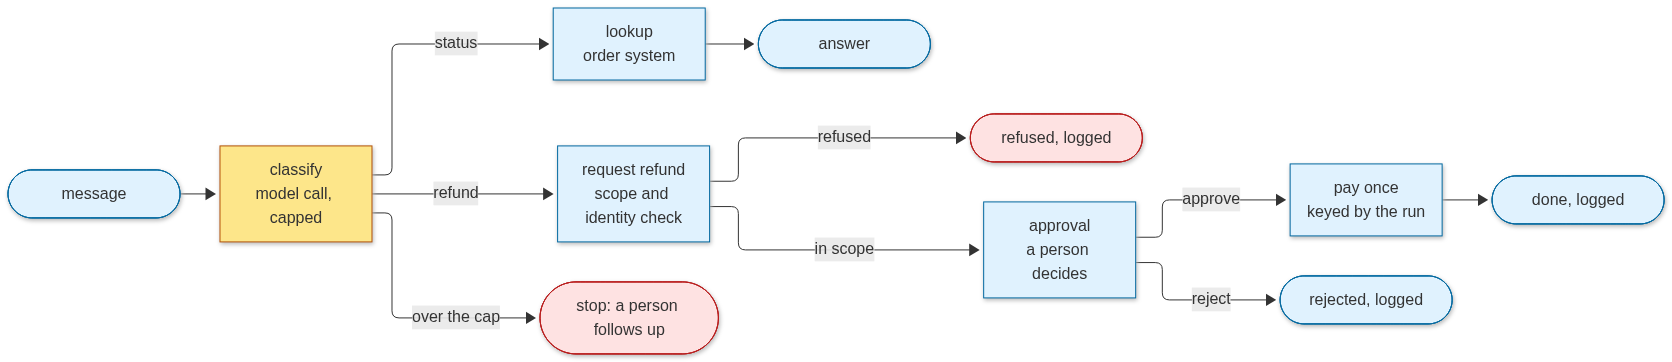

In [1]:
import sys; sys.path.insert(0, "../../..")  # the topic folder: llm_setup.py, graph_view.py and tut_env.py live there

from graph_view import show_mermaid

show_mermaid("""
flowchart LR
  M(["message"]) --> C["classify<br/>model call, capped"]
  C -->|status| L["lookup<br/>order system"] --> A(["answer"])
  C -->|refund| R["request refund<br/>scope and identity check"]
  R -->|refused| X(["refused, logged"])
  R -->|in scope| H["approval<br/>a person decides"]
  H -->|approve| P["pay once<br/>keyed by the run"] --> D(["done, logged"])
  H -->|reject| J(["rejected, logged"])
  C -->|over the cap| S(["stop: a person follows up"])
  classDef model fill:#fde68a,stroke:#b45309
  classDef code fill:#e0f2fe,stroke:#0369a1
  classDef stop fill:#fee2e2,stroke:#b91c1c
  class C model
  class M,L,A,R,H,P,D,J code
  class X,S stop
""")

## Requirements
The desk must:

1. classify each message with the model, with a spend cap of three calls per ticket;
2. answer order status from the order system, and never from the model's memory;
3. pause every refund for a person, and pay only after an approval written by a person;
4. pay each refund once, even when the run is retried or resumed;
5. refuse any write the agent's identity is not allowed to make, and log the refusal;
6. log every decision with the agent, the tool, the numbers and the reason, and no customer text;
7. pass the release gate of lesson 32 before it ships.

## Build it
You build the desk in four steps: the setup and the audit, the nodes, the wiring, and the runs. The release review that checks the seven
requirements is in the reference solution at the end. Every step's cell runs before the next one.

**Step 1 · the setup and the data (no call yet).** The order rows, the ledger and the audit list. The ledger is keyed by the run id, so a retry
cannot pay twice. The audit will hold decisions and numbers only.

In [2]:
import json
import sqlite3
from datetime import datetime, timezone
from pathlib import Path
from typing import Literal

from langgraph.checkpoint.memory import InMemorySaver
from langgraph.graph import END, START, StateGraph
from langgraph.types import Command, interrupt
from typing_extensions import TypedDict

ORDERS = json.loads((Path("../../../data") / "support_eval.json").read_text())["world"]["orders"]
LAB = Path("../../../data/lg38").resolve()
LAB.mkdir(parents=True, exist_ok=True)
LEDGER = sqlite3.connect(LAB / "ledger.db")
LEDGER.execute("CREATE TABLE IF NOT EXISTS ledger (run_id TEXT PRIMARY KEY, order_id TEXT, amount REAL)")
LEDGER.execute("DELETE FROM ledger")
LEDGER.commit()
AUDIT: list[dict] = []
SCOPES = {"desk-agent": {"lookup_order", "request_refund"},  # the desk may ask for a refund
          "payments-agent": {"pay_refund"}}                  # only the payments agent pays
SPEND_CAP_CALLS = 3
print("orders in the table:", len(ORDERS), "· spend cap per ticket:", SPEND_CAP_CALLS)

orders in the table: 12 · spend cap per ticket: 3


**Step 1b · the audit and the scope check (no call yet).** `audit` appends one decision to the log. `can` is the scope check: it asks whether an
agent may make an action, and it writes the answer to the audit log either way.

In [3]:
def audit(agent: str, action: str, args: dict, decision: str, reason: str) -> None:
    AUDIT.append({"at": datetime.now(timezone.utc).isoformat(timespec="seconds"), "agent": agent, "action": action,
                  "args": {k: v for k, v in args.items() if k in ("order_id", "amount")}, "decision": decision, "reason": reason})


def can(agent: str, action: str, args: dict) -> bool:
    ok = action in SCOPES.get(agent, set())
    audit(agent, action, args, "allowed" if ok else "refused", "in scope" if ok else "not in scope for this agent")
    return ok

**Step 2 · the state, classify and lookup (no call yet).** `DeskState` is the graph's memory: every node reads it and returns the part it changes.
`classify` is the only model call in the graph, and it stops calling once the cap is reached. `lookup` reads the order system, never the model's memory.

In [4]:
class DeskState(TypedDict):
    message: str
    intent: str
    order_id: str
    calls: int
    spent: float
    reply: str
    decision: str
    paid: bool


def classify(state: DeskState) -> dict:
    if state["calls"] >= SPEND_CAP_CALLS:
        return {"intent": "stop", "reply": "I need a person to follow up on this one."}
    reply = llm.invoke("Classify the message as exactly one word: status, refund or other.\n\n" + state["message"]).text
    intent = reply.strip().lower() if reply.strip().lower() in ("status", "refund") else "other"
    digits = [w.strip("?.,") for w in state["message"].split() if w.strip("?.,").isdigit()]
    return {"intent": intent, "order_id": digits[0] if digits else "", "calls": state["calls"] + 1}


def lookup(state: DeskState) -> dict:
    row = ORDERS.get(state["order_id"])
    if row is None:
        return {"reply": "Please send the four-digit order number from your confirmation email."}
    return {"reply": f"Order {state['order_id']} is {row['status']}, {row['days_late']} days late."}

**Step 2b · the refund nodes (no call yet).** `request_refund` asks `can` whether the desk may make the request; a refused request ends the run.
`approval` pauses the run with `interrupt`, which saves it until a person answers. `pay` runs only after an approve, under the agent that is
allowed to pay, and writes the ledger row keyed by the run id.

In [5]:
def request_refund(state: DeskState) -> dict:
    args = {"order_id": state["order_id"], "amount": ORDERS.get(state["order_id"], {}).get("total", 0)}
    if not can("desk-agent", "request_refund", args):
        return {"reply": "This request is being reviewed by a person.", "decision": "refused"}
    return {"decision": "waiting"}


def approval(state: DeskState) -> dict:
    verdict = interrupt({"question": "Approve this refund?", "order_id": state["order_id"]})  # the run pauses here, saved
    audit("reviewer", "approve_refund", {"order_id": state["order_id"]}, verdict["decision"], "a person decided")
    return {"decision": verdict["decision"]}


def pay(state: DeskState, config) -> dict:
    run_id = config["configurable"]["thread_id"]  # the run id is the idempotency key
    amount = ORDERS[state["order_id"]]["total"]
    if not can("payments-agent", "pay_refund", {"order_id": state["order_id"], "amount": amount}):
        return {"reply": "The payment is held for a person.", "paid": False}
    LEDGER.execute("INSERT OR IGNORE INTO ledger VALUES (?, ?, ?)", (run_id, state["order_id"], amount))
    LEDGER.commit()
    return {"paid": True, "reply": "Your refund has been approved and paid."}

**Step 2c · the routes and the wiring (no call yet).** A route is a function that picks the next node. `StateGraph` collects the nodes and the
edges, and `compile` turns them into a runnable graph (Step 3).

In [6]:
def route_intent(state: DeskState) -> Literal["lookup", "request_refund", "__end__"]:
    if state["intent"] == "status":
        return "lookup"
    return "request_refund" if state["intent"] == "refund" else END


def route_request(state: DeskState) -> Literal["approval", "__end__"]:
    return END if state.get("decision") == "refused" else "approval"


def route_decision(state: DeskState) -> Literal["pay", "__end__"]:
    return "pay" if state["decision"] == "approve" else END


g = StateGraph(DeskState)
for name, fn in [("classify", classify), ("lookup", lookup), ("request_refund", request_refund),
                 ("approval", approval), ("pay", pay)]:
    g.add_node(name, fn)
g.add_edge(START, "classify")
g.add_conditional_edges("classify", route_intent, {"lookup": "lookup", "request_refund": "request_refund", END: END})
g.add_edge("lookup", END)
g.add_conditional_edges("request_refund", route_request, {"approval": "approval", END: END})
g.add_conditional_edges("approval", route_decision, {"pay": "pay", END: END})
g.add_edge("pay", END)
print("nodes:", ", ".join(n for n in g.nodes if not n.startswith("__")))

nodes: classify, lookup, request_refund, approval, pay


**Step 3 · the model and the desk (1 model call per classified message).** Three course helpers appear here, each explained once. `llm_replay`
records the model's answers on the first run and replays them, so the lesson runs offline with no key. `get_llm` is the course's shared model
setup (the course model on Vertex AI); the thinking budget is turned down because classifying a message is an easy task. `show_graph` draws
the compiled graph from the public Mermaid service, and falls back to text when it is offline. `InMemorySaver` is a checkpointer that keeps the
paused runs in this process's memory: a paused refund resumes in the same process, and a restarted process needs the durable store of lesson 35.

LLM mode: replay (38_capstone-support-desk.yaml)


Gemini on Vertex AI · API key loaded: True


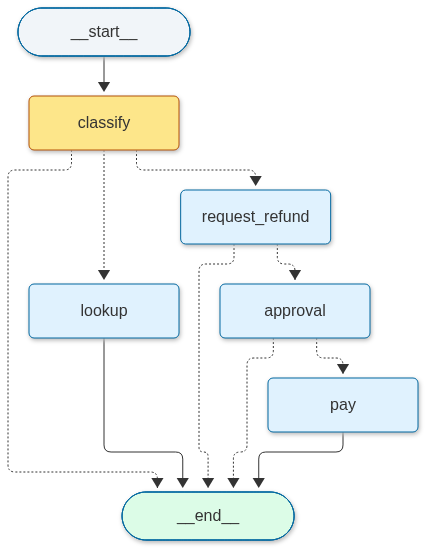

In [7]:
import llm_replay
llm_replay.start("38_capstone-support-desk")

from llm_setup import get_llm
from graph_view import show_graph

llm = get_llm(thinking_budget=0)
desk = g.compile(checkpointer=InMemorySaver())
show_graph(desk, model_nodes=("classify",))

**Step 4 · a status question and a refund (1 model call each).** `run` starts one thread, which is one ticket with its own run id. The status
question is answered from the order system. The refund pauses for a person; the same run then resumes with an approval and is paid once. A repeated
resume must not pay a second time.

In [8]:
def run(thread: str, message: str):
    cfg = {"configurable": {"thread_id": thread}}
    state = {"message": message, "intent": "", "order_id": "", "calls": 0, "spent": 0.0, "reply": "",
             "decision": "", "paid": False}
    return desk.invoke(state, cfg), cfg


status_out, _ = run("t-status", "Where is order 1003?")
print("status:", status_out["reply"])

refund_out, refund_cfg = run("t-refund", "Order 1003 never arrived. Please refund me.")
print("refund waits for:", [i.value["question"] for i in refund_out.get("__interrupt__", [])],
      "· paid so far:", LEDGER.execute("SELECT COUNT(*) FROM ledger").fetchone()[0])
final = desk.invoke(Command(resume={"decision": "approve"}), refund_cfg)
desk.invoke(Command(resume={"decision": "approve"}), refund_cfg)  # a repeated resume must not pay twice
print("after approval:", final.get("reply"), "· paid rows:", LEDGER.execute("SELECT COUNT(*) FROM ledger WHERE run_id='t-refund'").fetchone()[0])

status: Order 1003 is lost, 9 days late.
refund waits for: ['Approve this refund?'] · paid so far: 0
after approval: Your refund has been approved and paid. · paid rows: 1


**Step 5 · a rejected refund (1 model call).** The same pause, this time answered with a reject. A rejected refund must leave no ledger row. The
model recording is closed at the end of this cell, after the last call of the lesson.

In [9]:
rejected_out, rejected_cfg = run("t-rejected", "Order 1093 was lost. I want my money back.")
desk.invoke(Command(resume={"decision": "reject"}), rejected_cfg)
print("rejected paid rows:", LEDGER.execute("SELECT COUNT(*) FROM ledger WHERE run_id='t-rejected'").fetchone()[0])
llm_replay.stop()  # the last model call of this lesson

rejected paid rows: 0


## Reference solution
This is the release review. It reads the three runs and the audit log, and prints one PASS or FAIL line per requirement. Its checks need the
model's answers from Step 4 and Step 5, so the cell is skipped only when there is no recording and no key. Its first cell builds the checks:
it also asks the desk to pay a refund under its own agent, which the scope check must refuse and log.

In [10]:
def contains_customer_text(entry: dict) -> bool:
    return any(isinstance(v, str) and len(v) > 40 for v in entry["args"].values())


def paid_rows(run_id: str) -> int:
    return LEDGER.execute("SELECT COUNT(*) FROM ledger WHERE run_id = ?", (run_id,)).fetchone()[0]


refused = not can("desk-agent", "pay_refund", {"order_id": "1003"})  # the desk may not pay: refused and logged
checks = {
    "1 · classification is capped": status_out["calls"] <= SPEND_CAP_CALLS and refund_out["calls"] <= SPEND_CAP_CALLS,
    "2 · status comes from the order system": "lost" in status_out["reply"] or "in transit" in status_out["reply"],
    "3 · a refund waits for a person": bool(refund_out.get("__interrupt__")),
    "4 · a refund is paid once": paid_rows("t-refund") == 1,
    "5 · a write outside the scope is refused and logged": refused and AUDIT[-1]["decision"] == "refused",
    "5 · a rejected refund is not paid": paid_rows("t-rejected") == 0,
    "6 · the audit holds no customer text": not any(contains_customer_text(e) for e in AUDIT),
    "6 · every decision names its agent and reason": all(e["agent"] and e["reason"] for e in AUDIT),
}
for name, ok in checks.items():
    print("PASS" if ok else "FAIL", "-", name)
print(f"audit entries: {len(AUDIT)} · last: {AUDIT[-1]['action']} → {AUDIT[-1]['decision']}")

PASS - 1 · classification is capped
PASS - 2 · status comes from the order system
PASS - 3 · a refund waits for a person
PASS - 4 · a refund is paid once
PASS - 5 · a write outside the scope is refused and logged
PASS - 5 · a rejected refund is not paid
PASS - 6 · the audit holds no customer text
PASS - 6 · every decision names its agent and reason
audit entries: 6 · last: pay_refund → refused


The release gate (lesson 32) comes last. It runs the golden set in `data/support_eval.json` through a scripted stand-in: the stand-in only looks
up orders (it never issues a refund), so it scores the lookup tasks, and it does not call the model. The score is compared with the baseline saved
in lesson 32, read from `data/lg32/baseline.json`; if that file is missing, the course default of 12 is used. The gate result is requirement 7.

In [11]:
import re

TASKS = json.loads((Path("../../../data") / "support_eval.json").read_text())["tasks"]
BASELINE_FILE = Path("../../../data/lg32/baseline.json")
baseline = json.loads(BASELINE_FILE.read_text())["passed"] if BASELINE_FILE.exists() else 12


def scripted(request: str) -> tuple[dict, list[str]]:
    return {"refunds": {}, "tickets": []}, (["lookup_order"] if re.search(r"\b\d{4}\b", request) else [])


score = 0
for task in TASKS:
    end, called = scripted(task["request"])
    if (not any(t in called for t in task.get("forbidden_tools", []))
            and all(t in called for t in task.get("must_call", [])) and end == task["expected_end"]):
        score += 1
gate_ok = score >= baseline
print("PASS" if gate_ok else "FAIL", f"- 7 · release gate: score {score} against the baseline {baseline}")
print("RELEASE:", "approved" if all(checks.values()) and gate_ok else "blocked")

PASS - 7 · release gate: score 12 against the baseline 12
RELEASE: approved


**What just happened** — the printed numbers, from the run above.
- The status question was answered from the order system: "Order 1003 is lost, 9 days late." It made one model call, to classify the message.
- The refund paused and waited for a person ("Approve this refund?") with 0 rows paid; after the approval it had 1 paid row, even though the approval was sent twice.
- The rejected refund left 0 paid rows.
- The audit log holds 6 entries, and the scope check refused the desk's own pay request; the release gate scored 12 against the baseline of 12, so the release is approved.

## Key terms
- **Audit log** — the record of each decision with its agent, action, numbers and reason, and no customer text.
- **Checkpointer** — the store that saves a paused graph run so it can resume later under its thread id.
- **Golden set** — a fixed list of test requests with the expected result, used to score a release.
- **Idempotency key** — an identifier that makes a repeated action count once; here the run id.
- **Interrupt** — a pause in a graph run that waits for a person's answer before it continues.
- **Release gate** — a check that must pass before a change ships; it is compared with a saved baseline.
- **Scope** — the set of actions an agent is allowed to take.
- **Spend cap** — a limit on the model calls one ticket may use.

## At work
- A production agent is reviewed as a whole: the parts meet where they fail. Teams run a checklist like this one before every release, and keep it in
  the repository next to the code.
- The capstone's refund path is the same design as lessons 13, 35 and 34 together: a pause, a key, a gate and a log. Each of those is tested alone
  and then together here.
- The next step after the course is the real stack: a managed workflow engine for durable runs, a real order system, and the team's own evals.

## Common mistakes
1. **Reading an order that does not exist.** Indexing the order table with a key that is not there raises an error. `lookup` avoids it with `.get()`
   and asks the customer for the number instead.

In [12]:
ORDERS["9999"]["status"]  # raises KeyError: order 9999 is not in the table

KeyError: '9999'

The fix is the `.get()` pattern that `lookup` already uses: a missing key returns `None`, and the node replies instead of crashing.

2. **Testing each part alone and never together.** Each part can pass its own test while the desk as a whole fails, so the checklist runs the whole
   desk.
3. **A release with a failed check.** One FAIL blocks the release. Fix the part, not the check.
4. **A checklist that is not kept.** A review that lives in someone's head is not repeated. Keep it in the repository.

## Try it
Write `release_decision(check_results, gate_passed)` that returns `"approved"` only when every check is `True` and the gate passed, and `"blocked"`
otherwise. Test it on `{"a": True, "b": False}` with the gate passed, and on `{"a": True, "b": True}` with the gate passed. No model call is needed.

In [13]:
# your code here

**Answer** — try it first, then expand the hidden cell below.

In [14]:
def release_decision(check_results: dict, gate_passed: bool) -> str:
    return "approved" if all(check_results.values()) and gate_passed else "blocked"


print(release_decision({"a": True, "b": False}, True), release_decision({"a": True, "b": True}, True))  # blocked approved

blocked approved


## Recap
- One graph holds the desk: a capped model step, a scoped and keyed write behind a pause, an audit of every decision, and a release gate.
- Each requirement has a check that reads the run or the log, and the release is blocked by any failed check.
- The parts from lessons 05 to 37 meet in this graph, and the checklist is what finds where they fail.

**Interview:** "Walk me through how you would ship a support agent that can refund customers." Strong answer: "The model classifies within a spend cap.
Any refund pauses for a person, and the payment is keyed, so a retry pays once. Every write is gated by scope, every decision is logged without
customer text, and a release gate runs the golden set against a saved baseline before the change ships."